# DGT 자부두 환적 타임라인 정리 및 총 소요시간 분석

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
DGT_DGT_CSV_PATH = './data/DGT_DGT_2025.csv'
df = pd.read_csv(DGT_DGT_CSV_PATH)

In [4]:
df

,컨테이너번호,Class,적/공,Size/Type,화물종류,중량(kg),Seal No,BL No,양하항,적하항,...,양하모선항차,적하모선명,적하모선항차,선내위치,야드 장치 시간,트럭 진입 시간,온샤시 시간,경과료 Free Date,냉동료 Free Date,반출예정일
0,APZU3703984,TL,M,20/GE(2210),M,2230.0,NaN,WO03197300A,CNTAO,KITRW,...,PCEE-002/2025,LING YUN HE,CLYH-038/2025,NaN,2025-10-11 11:37,NaN,2025-11-12 20:51,NaN,NaN,NaN
1,AXIU6229942,TL,F,20/RF(22R1),R,20346.0,NaN,SYDA70895100,JPYOK,AUBNE,...,HHGR-001/2025,HONOR VOYAGER,HNVY-013/2025,NaN,2025-03-26 03:13,NaN,2025-04-01 16:04,NaN,NaN,NaN
2,BEAU2047832,TL,F,20/GE(2210),G,4641.0,NaN,TYOM59150000,BRSSZ,JPSMZ,...,OCNF-023/2025,NYK FUTAGO,ONFG-003/2025,NaN,2025-11-05 18:41,NaN,2025-11-12 20:41,NaN,NaN,NaN
3,BEAU4925140,TL,F,40/GE(4510),G,8763.0,NaN,SHKA041638,USLGB,CNSHK,...,KKSL-001/2025,KMTC MUNDRA,KKMU-005/2025,NaN,2025-10-02 08:32,NaN,2025-10-11 02:42,NaN,NaN,NaN
4,BEAU5175441,TL,F,40/GE(45G1),G,10435.0,NaN,CN03873000,PGMTK,TWTXG,...,SWUC-002/2025,PORT VILA CHIEF,SWPV-001/2025,NaN,2025-03-18 04:00,NaN,2025-03-24 23:59,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
151,TRHU7393341,TL,F,40/GE(4510),G,8880.0,NaN,TYOFJ3408700,SGSIN,JPKWS,...,OCNF-018/2025,HYUNDAI DYNASTY,HHDT-002/2025,NaN,2025-09-28 11:16,NaN,2025-10-07 15:18,NaN,NaN,NaN
152,TRHU8326190,TL,F,40/GE(45G1),G,29620.0,NaN,FREF04548700,JPSBS,SGSIN,...,OSOK-002/2025,ITX EHIME,IIEM-010/2025,NaN,2025-08-03 02:50,NaN,2025-08-07 06:25,NaN,NaN,NaN
153,TXGU5020559,TL,F,40/GE(4510),G,24500.0,NaN,PKG2651501,CNXGG,MYPKG,...,W522-008/2025,SUNNY CLOVER,KSCV-004/2025,NaN,2025-11-24 18:33,NaN,2025-12-12 16:14,NaN,NaN,NaN
154,TXGU8528991,TX,F,40/GE(45G1),G,24716.0,NaN,HDMUDALA92878900,JPHKT,USSAV,...,YWTY-001/2025,DONGJIN FIDES,DJFD-001/2025,NaN,2025-02-17 11:53,NaN,2025-02-23 04:26,NaN,NaN,NaN


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 32 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   컨테이너번호         156 non-null    str    
 1   Class          156 non-null    str    
 2   적/공            156 non-null    str    
 3   Size/Type      156 non-null    str    
 4   화물종류           156 non-null    str    
 5   중량(kg)         156 non-null    float64
 6   Seal No        0 non-null      float64
 7   BL No          156 non-null    str    
 8   양하항            156 non-null    str    
 9   적하항            156 non-null    str    
 10  야드위치           0 non-null      float64
 11  반입방식           156 non-null    str    
 12  반입시간           156 non-null    str    
 13  반출방식           156 non-null    str    
 14  반출시간           156 non-null    str    
 15  반입차량번호         0 non-null      float64
 16  반출차량번호         0 non-null      float64
 17  손상여부           1 non-null      str    
 18  IMDG           9 non-

In [9]:
df.columns

Index(['컨테이너번호', 'Class', '적/공', 'Size/Type', '화물종류', '중량(kg)', 'Seal No',
       'BL No', '양하항', '적하항', '야드위치', '반입방식', '반입시간', '반출방식', '반출시간', '반입차량번호',
       '반출차량번호', '손상여부', 'IMDG', 'UNNO', '온도', '양하모선명', '양하모선항차', '적하모선명',
       '적하모선항차', '선내위치', '야드 장치 시간', '트럭 진입 시간', '온샤시 시간', '경과료 Free Date',
       '냉동료 Free Date', '반출예정일'],
      dtype='str')

In [7]:
start_date = '2025-01-01 00:00:00'
end_date = '2025-12-31 23:59:59'

filtered_df = df[
    (df['반입시간'] >= start_date) & (df['반입시간'] <= end_date) &
    (df['반출시간'] >= start_date) & (df['반출시간'] <= end_date)
]

df.shape

(156, 32)

In [6]:
# 공컨테이너는 환적 과정에서의 병목을 파악하기에 부적절하므로 제외하고 적컨으로만 분석 진행
full_con = df[df['적/공'] == 'F']
print(full_con)

          컨테이너번호 Class 적/공    Size/Type 화물종류   중량(kg)  Seal No  \
1    AXIU6229942    TL   F  20/RF(22R1)    R  20346.0      NaN   
2    BEAU2047832    TL   F  20/GE(2210)    G   4641.0      NaN   
3    BEAU4925140    TL   F  40/GE(4510)    G   8763.0      NaN   
4    BEAU5175441    TL   F  40/GE(45G1)    G  10435.0      NaN   
8    BMOU1263472    TL   F  20/GE(22G1)    H  26432.0      NaN   
..           ...   ...  ..          ...  ...      ...      ...   
151  TRHU7393341    TL   F  40/GE(4510)    G   8880.0      NaN   
152  TRHU8326190    TL   F  40/GE(45G1)    G  29620.0      NaN   
153  TXGU5020559    TL   F  40/GE(4510)    G  24500.0      NaN   
154  TXGU8528991    TX   F  40/GE(45G1)    G  24716.0      NaN   
155  UETU2184932    TL   F  20/GE(22G1)    G  25280.0      NaN   

                BL No    양하항    적하항  ...         양하모선항차            적하모선명  \
1        SYDA70895100  JPYOK  AUBNE  ...  HHGR-001/2025    HONOR VOYAGER   
2        TYOM59150000  BRSSZ  JPSMZ  ...  OCNF-023/2025

In [11]:
# 분석에 필요 없는 컬럼 모두 제거
df_time = full_con[['컨테이너번호', '반입시간', '야드 장치 시간', '온샤시 시간', '반출시간']]
df_time

,컨테이너번호,반입시간,야드 장치 시간,온샤시 시간,반출시간
1,AXIU6229942,2025-03-26 02:26:00,2025-03-26 03:13:00,2025-04-01 16:04:00,2025-04-01 16:36:00
2,BEAU2047832,2025-11-05 18:34:00,2025-11-05 18:41:00,2025-11-12 20:41:00,2025-11-12 21:04:00
3,BEAU4925140,2025-10-02 08:26:00,2025-10-02 08:32:00,2025-10-11 02:42:00,2025-10-11 03:18:00
4,BEAU5175441,2025-03-18 03:52:00,2025-03-18 04:00:00,2025-03-24 23:59:00,2025-03-25 01:29:00
8,BMOU1263472,2025-08-06 16:15:00,2025-08-06 16:27:00,2025-08-25 01:03:00,2025-08-25 01:50:00
...,...,...,...,...,...
151,TRHU7393341,2025-09-28 10:55:00,2025-09-28 11:16:00,2025-10-07 15:18:00,2025-10-07 15:30:00
152,TRHU8326190,2025-08-03 02:34:00,2025-08-03 02:50:00,2025-08-07 06:25:00,2025-08-07 07:02:00
153,TXGU5020559,2025-11-24 18:20:00,2025-11-24 18:33:00,2025-12-12 16:14:00,2025-12-12 16:44:00
154,TXGU8528991,2025-02-17 11:44:00,2025-02-17 11:53:00,2025-02-23 04:26:00,2025-02-23 05:44:00


In [12]:
# 계산을 위해 반입시간, 반출시간, 온샤시 시간, 야드 장치 시간 자료 형식 날짜로 변경
df_time['반입시간'] = pd.to_datetime(df_time['반입시간'])
df_time['반출시간'] = pd.to_datetime(df_time['반출시간'])
df_time['온샤시 시간'] = pd.to_datetime(df_time['온샤시 시간'])
df_time['야드 장치 시간'] = pd.to_datetime(df_time['야드 장치 시간'])

In [13]:
df_time.info()

<class 'pandas.DataFrame'>
Index: 124 entries, 1 to 155
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   컨테이너번호    124 non-null    str           
 1   반입시간      124 non-null    datetime64[us]
 2   야드 장치 시간  124 non-null    datetime64[us]
 3   온샤시 시간    124 non-null    datetime64[us]
 4   반출시간      124 non-null    datetime64[us]
dtypes: datetime64[us](4), str(1)
memory usage: 5.8 KB


In [15]:
# 총 소요시간 구하기
df_time['총소요시간'] = (df_time['반출시간'] - df_time['반입시간']).dt.total_seconds() / 3600  # 시간 단위
# 만약 '분(minute)' 단위로 구하고 싶다면 아래 주석처럼 60으로 나누거나 .dt.total_seconds() / 60을 사용하세요
# df['총소요시간'] = (df['반출시간'] - df['반입시간']).dt.total_seconds() / 60  # 분 단위

df_time

,컨테이너번호,반입시간,야드 장치 시간,온샤시 시간,반출시간,총소요시간
1,AXIU6229942,2025-03-26 02:26:00,2025-03-26 03:13:00,2025-04-01 16:04:00,2025-04-01 16:36:00,158.166667
2,BEAU2047832,2025-11-05 18:34:00,2025-11-05 18:41:00,2025-11-12 20:41:00,2025-11-12 21:04:00,170.500000
3,BEAU4925140,2025-10-02 08:26:00,2025-10-02 08:32:00,2025-10-11 02:42:00,2025-10-11 03:18:00,210.866667
4,BEAU5175441,2025-03-18 03:52:00,2025-03-18 04:00:00,2025-03-24 23:59:00,2025-03-25 01:29:00,165.616667
8,BMOU1263472,2025-08-06 16:15:00,2025-08-06 16:27:00,2025-08-25 01:03:00,2025-08-25 01:50:00,441.583333
...,...,...,...,...,...,...
151,TRHU7393341,2025-09-28 10:55:00,2025-09-28 11:16:00,2025-10-07 15:18:00,2025-10-07 15:30:00,220.583333
152,TRHU8326190,2025-08-03 02:34:00,2025-08-03 02:50:00,2025-08-07 06:25:00,2025-08-07 07:02:00,100.466667
153,TXGU5020559,2025-11-24 18:20:00,2025-11-24 18:33:00,2025-12-12 16:14:00,2025-12-12 16:44:00,430.400000
154,TXGU8528991,2025-02-17 11:44:00,2025-02-17 11:53:00,2025-02-23 04:26:00,2025-02-23 05:44:00,138.000000


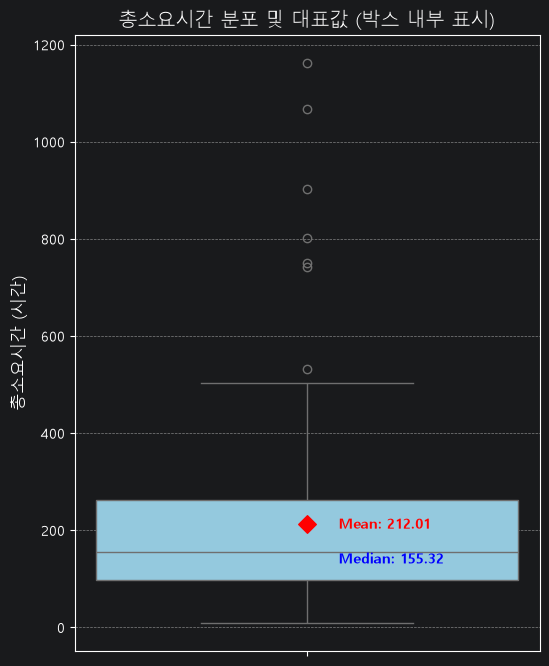

In [22]:
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 1. 평균값과 중앙값 계산
mean_val = df_time['총소요시간'].mean()
median_val = df_time['총소요시간'].median()

# 2. 박스플롯 그리기
plt.figure(figsize=(6, 8))
ax = sns.boxplot(y=df_time['총소요시간'], color='skyblue', width=0.4)

# 3. 평균값 마커와 텍스트를 박스 내부(x=0 근처)로 배치
plt.scatter(0, mean_val, color='red', marker='D', s=80, zorder=5)
# x 좌표를 0.03 정도로 주어 박스 안쪽 왼편에 텍스트가 위치하도록 설정
plt.text(0.03, mean_val, f'Mean: {mean_val:.2f}', color='red', va='center', fontweight='bold', fontsize=10)

# 4. 중앙값 텍스트도 박스 내부 중앙선 근처에 배치
# 중앙값 선(median_val)보다 살짝 위나 아래로 여백을 주어 겹치지 않게 조절 가능합니다.
plt.text(0.03, median_val - 15, f'Median: {median_val:.2f}', color='blue', va='center', fontweight='bold', fontsize=10)

# 5. 그래프 꾸미기
plt.title('총소요시간 분포 및 대표값 (박스 내부 표시)', fontsize=14)
plt.ylabel('총소요시간 (시간)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()